In [ ]:
# ============================================================
# CELDA 1. INSTALACIÓN E IMPORTACIÓN DE BIBLIOTECAS
# ============================================================

%pip -q install -U pandera seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandera.pandas as pa

from IPython.display import display

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Pandas:", pd.__version__)
print("Pandera:", pa.__name__)
print("Bibliotecas cargadas correctamente.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 535.0/535.0 kB 7.6 MB/s eta 0:00:00
Pandas: 2.2.3
Pandera: pandera.pandas
Bibliotecas cargadas correctamente.


In [ ]:

# ============================================================
# CELDA 2. CREACIÓN DEL DATASET
# ============================================================

np.random.seed(42)

n = 200

df = pd.DataFrame({
    "id_venta": range(1001, 1001 + n),

    "fecha": pd.date_range(
        start="2026-01-01",
        periods=n,
        freq="D"
    ),

    "cliente": [
        f"Cliente_{i}" for i in range(1, n + 1)
    ],

    "categoria": np.random.choice(
        ["Electrónica", "Hogar", "Ropa", "Alimentos"],
        size=n
    ),

    "cantidad": np.random.randint(1, 11, size=n),

    "precio_unitario": np.round(
        np.random.uniform(50, 2000, size=n), 2
    ),

    "satisfaccion": np.random.randint(1, 6, size=n)
})

# Introducir errores deliberadamente
df.loc[5, "cantidad"] = -3
df.loc[12, "precio_unitario"] = -150
df.loc[20, "categoria"] = "Categoría desconocida"
df.loc[25, "satisfaccion"] = 8
df.loc[30, "cliente"] = None
df.loc[40, "id_venta"] = df.loc[39, "id_venta"]

print("Dimensiones del dataset:", df.shape)
print("\nPrimeros registros:")
display(df.head(10))

print("\nTipos de datos:")
display(df.dtypes.to_frame("Tipo de dato"))


Dimensiones del dataset: (200, 7)

Primeros registros:


,id_venta,fecha,cliente,categoria,cantidad,precio_unitario,satisfaccion
0,1001,2026-01-01,Cliente_1,Ropa,7,545.62,3
1,1002,2026-01-02,Cliente_2,Alimentos,1,625.82,5
2,1003,2026-01-03,Cliente_3,Electrónica,4,678.97,4
3,1004,2026-01-04,Cliente_4,Ropa,4,1704.91,1
4,1005,2026-01-05,Cliente_5,Ropa,5,316.41,4
5,1006,2026-01-06,Cliente_6,Alimentos,-3,1432.38,1
6,1007,2026-01-07,Cliente_7,Electrónica,7,1128.00,1
7,1008,2026-01-08,Cliente_8,Electrónica,4,628.19,1
8,1009,2026-01-09,Cliente_9,Ropa,7,868.57,5
9,1010,2026-01-10,Cliente_10,Hogar,3,549.60,2



Tipos de datos:


,Tipo de dato
id_venta,int64
fecha,datetime64[ns]
cliente,object
categoria,object
cantidad,int64
precio_unitario,float64
satisfaccion,int64


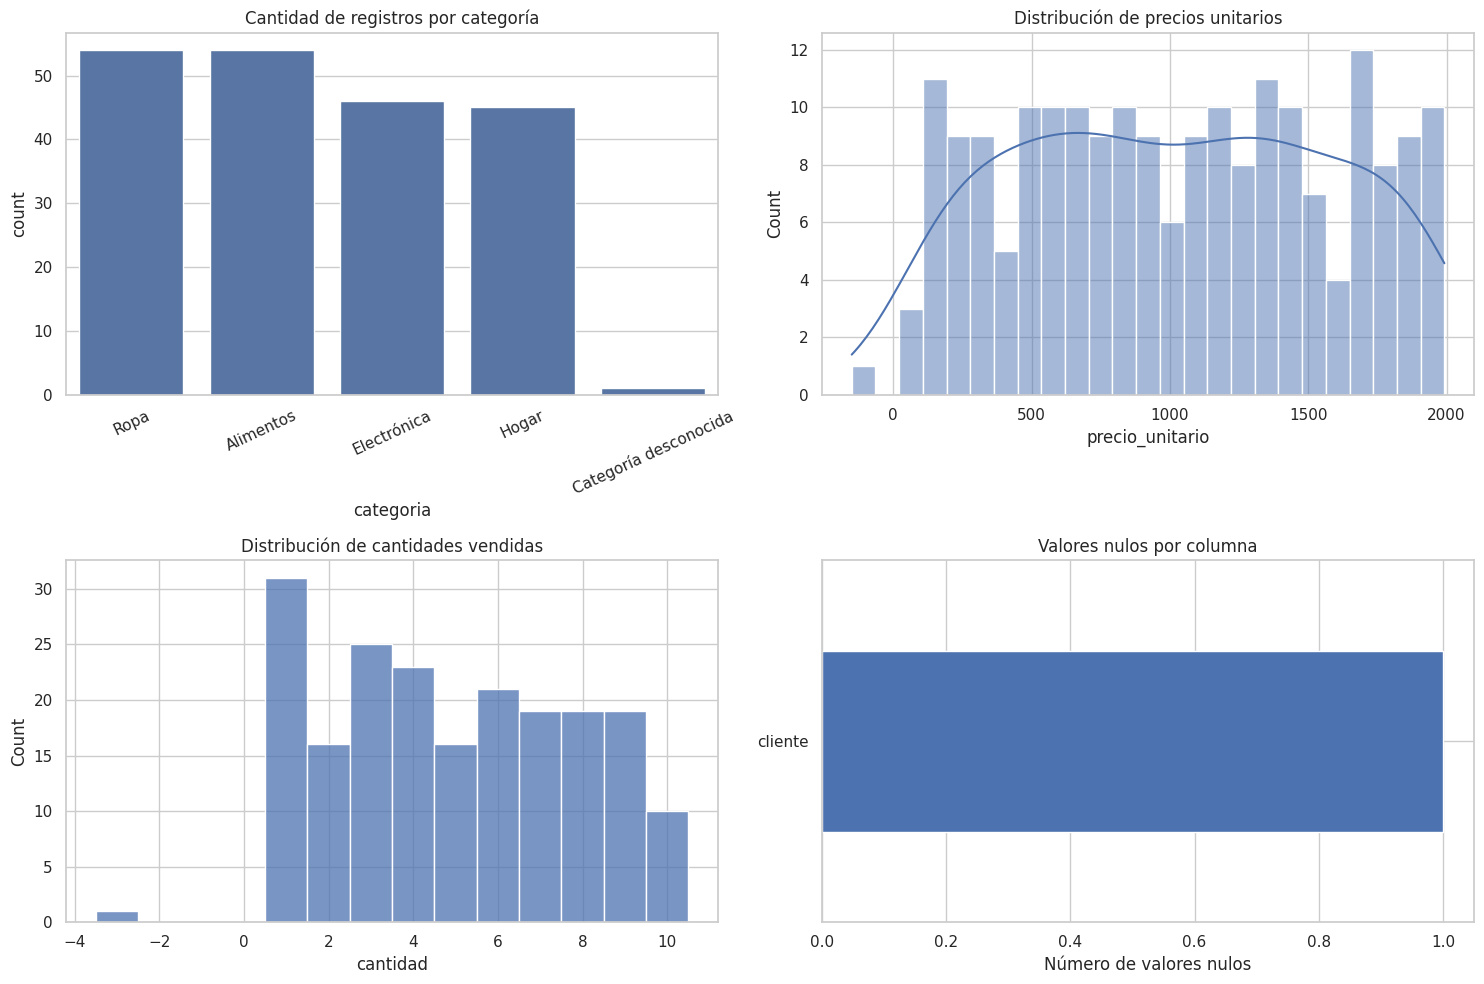

In [ ]:

# ============================================================
# CELDA 3. ANÁLISIS EXPLORATORIO
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Gráfica 1: ventas por categoría
sns.countplot(
    data=df,
    x="categoria",
    order=df["categoria"].value_counts().index,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Cantidad de registros por categoría")
axes[0, 0].tick_params(axis="x", rotation=25)

# Gráfica 2: distribución de precios
sns.histplot(
    data=df,
    x="precio_unitario",
    bins=25,
    kde=True,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Distribución de precios unitarios")

# Gráfica 3: distribución de cantidades
sns.histplot(
    data=df,
    x="cantidad",
    bins=15,
    discrete=True,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribución de cantidades vendidas")

# Gráfica 4: valores nulos por columna
nulos = df.isnull().sum()
nulos = nulos[nulos > 0]

if len(nulos) > 0:
    nulos.sort_values().plot.barh(ax=axes[1, 1])
else:
    axes[1, 1].text(
        0.5, 0.5, "No hay valores nulos",
        ha="center", va="center"
    )

axes[1, 1].set_title("Valores nulos por columna")
axes[1, 1].set_xlabel("Número de valores nulos")

plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# CELDA 4. DEFINICIÓN DEL ESQUEMA
# ============================================================

categorias_validas = [
    "Electrónica",
    "Hogar",
    "Ropa",
    "Alimentos"
]

esquema_ventas = pa.DataFrameSchema(
    {
        "id_venta": pa.Column(
            int,
            nullable=False
        ),

        "fecha": pa.Column(
            pa.DateTime,
            nullable=False
        ),

        "cliente": pa.Column(
            str,
            nullable=False
        ),

        "categoria": pa.Column(
            str,
            checks=pa.Check.isin(categorias_validas),
            nullable=False
        ),

        "cantidad": pa.Column(
            int,
            checks=pa.Check.ge(1),
            nullable=False
        ),

        "precio_unitario": pa.Column(
            float,
            checks=pa.Check.ge(0),
            nullable=False
        ),

        "satisfaccion": pa.Column(
            int,
            checks=pa.Check.isin([1, 2, 3, 4, 5]),
            nullable=False
        )
    },

    # El identificador no debe repetirse.
    unique=["id_venta"],

    # No permitir columnas adicionales.
    strict=True
)

print("Esquema de validación definido.")


Esquema de validación definido.


In [ ]:

# ============================================================
# CELDA 5. EJECUCIÓN DE LA VALIDACIÓN
# ============================================================

try:
    df_validado = esquema_ventas.validate(
        df,
        lazy=True
    )

    print("VALIDACIÓN EXITOSA")
    display(df_validado.head())

except pa.errors.SchemaErrors as error:
    print("SE DETECTARON ERRORES DE VALIDACIÓN")
    print("=" * 60)

    # Tabla con los errores encontrados
    errores = error.failure_cases

    display(errores)

    print("\nResumen por columna:")
    if "column" in errores.columns:
        display(
            errores.groupby("column")
            .size()
            .reset_index(name="Errores reportados")
            .sort_values("Errores reportados", ascending=False)
        )

except pa.errors.SchemaError as error:
    print("Error de validación:")
    print(error)


SE DETECTARON ERRORES DE VALIDACIÓN


,schema_context,column,check,check_number,failure_case,index
0,DataFrameSchema,id_venta,multiple_fields_uniqueness,None,1040,39
1,DataFrameSchema,id_venta,multiple_fields_uniqueness,None,1040,40
2,Column,cliente,not_nullable,None,None,30
3,Column,categoria,"isin(['Electrónica', 'Hogar', 'Ropa', 'Aliment...",0,Categoría desconocida,20
4,Column,cantidad,greater_than_or_equal_to(1),0,-3,5
5,Column,precio_unitario,greater_than_or_equal_to(0),0,-150.0,12
6,Column,satisfaccion,"isin([1, 2, 3, 4, 5])",0,8,25



Resumen por columna:


,column,Errores reportados
3,id_venta,2
0,cantidad,1
1,categoria,1
2,cliente,1
4,precio_unitario,1
5,satisfaccion,1


In [ ]:

# ============================================================
# CELDA 6. LIMPIEZA DE DATOS

df_limpio = df.copy()

# 1. Eliminar ventas con identificadores duplicados.
df_limpio = df_limpio.drop_duplicates(
    subset="id_venta",
    keep="first"
).copy()

# 2. Completar clientes sin nombre.
df_limpio["cliente"] = df_limpio["cliente"].fillna(
    "Cliente no identificado"
)

# 3. Sustituir categorías no reconocidas.
df_limpio.loc[
    ~df_limpio["categoria"].isin(categorias_validas),
    "categoria"
] = "Hogar"

# 4. Corregir cantidades menores que uno.
df_limpio["cantidad"] = df_limpio["cantidad"].clip(lower=1)

# 5. Reemplazar precios negativos por la mediana
#    de los precios válidos del dataset original.
mediana_precios = df.loc[
    df["precio_unitario"] >= 0,
    "precio_unitario"
].median()

df_limpio.loc[
    df_limpio["precio_unitario"] < 0,
    "precio_unitario"
] = mediana_precios

# 6. Limitar la satisfacción al rango permitido.
df_limpio["satisfaccion"] = df_limpio[
    "satisfaccion"
].clip(lower=1, upper=5)

# Comprobar el resultado con Pandera.
try:
    df_validado = esquema_ventas.validate(
        df_limpio,
        lazy=True
    )

    print("¡VALIDACIÓN EXITOSA!")
    print("Todos los registros cumplen el esquema.")
    print("Registros originales:", len(df))
    print("Registros finales:", len(df_validado))

    display(df_validado.head(10))

except pa.errors.SchemaErrors as error:
    print("Aún existen errores:")
    display(error.failure_cases)


¡VALIDACIÓN EXITOSA!
Todos los registros cumplen el esquema.
Registros originales: 200
Registros finales: 199


,id_venta,fecha,cliente,categoria,cantidad,precio_unitario,satisfaccion
0,1001,2026-01-01,Cliente_1,Ropa,7,545.62,3
1,1002,2026-01-02,Cliente_2,Alimentos,1,625.82,5
2,1003,2026-01-03,Cliente_3,Electrónica,4,678.97,4
3,1004,2026-01-04,Cliente_4,Ropa,4,1704.91,1
4,1005,2026-01-05,Cliente_5,Ropa,5,316.41,4
5,1006,2026-01-06,Cliente_6,Alimentos,1,1432.38,1
6,1007,2026-01-07,Cliente_7,Electrónica,7,1128.00,1
7,1008,2026-01-08,Cliente_8,Electrónica,4,628.19,1
8,1009,2026-01-09,Cliente_9,Ropa,7,868.57,5
9,1010,2026-01-10,Cliente_10,Hogar,3,549.60,2


Resumen de calidad:


,Estado,Filas problemáticas
0,Antes de limpiar,7
1,Después de limpiar,0


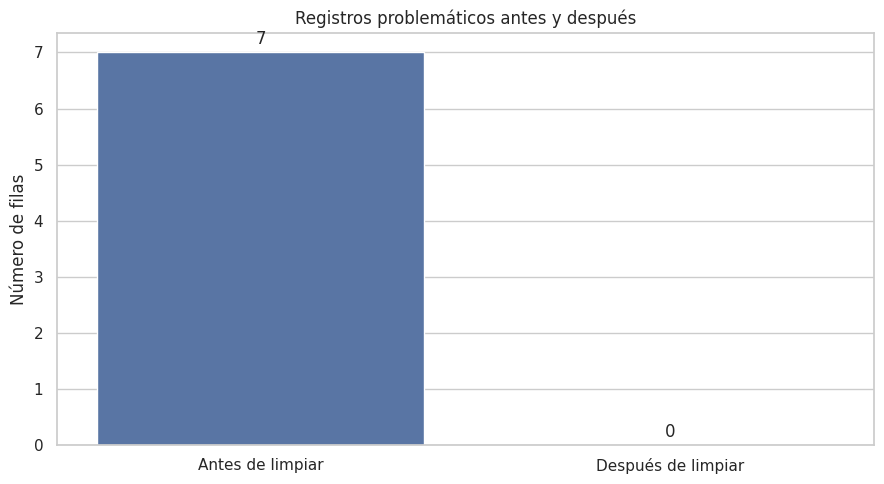

In [ ]:

# ============================================================
# CELDA 7. COMPARACIÓN DE CALIDAD
# ============================================================

def contar_filas_problematicas(data):
    """Cuenta filas que incumplen al menos una regla."""

    problemas = pd.DataFrame(index=data.index)

    problemas["ID duplicado"] = data["id_venta"].duplicated(
        keep=False
    )

    problemas["Cliente nulo"] = data["cliente"].isna()

    problemas["Categoría inválida"] = ~data[
        "categoria"
    ].isin(categorias_validas)

    problemas["Cantidad inválida"] = data["cantidad"] < 1

    problemas["Precio inválido"] = data[
        "precio_unitario"
    ].isna() | (data["precio_unitario"] < 0)

    problemas["Satisfacción inválida"] = ~data[
        "satisfaccion"
    ].isin([1, 2, 3, 4, 5])

    return problemas.any(axis=1).sum()


filas_antes = contar_filas_problematicas(df)
filas_despues = contar_filas_problematicas(df_limpio)

resumen = pd.DataFrame({
    "Estado": ["Antes de limpiar", "Después de limpiar"],
    "Filas problemáticas": [filas_antes, filas_despues]
})

print("Resumen de calidad:")
display(resumen)

# Gráfica comparativa
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=resumen,
    x="Estado",
    y="Filas problemáticas"
)

ax.set_title("Registros problemáticos antes y después")
ax.set_xlabel("")
ax.set_ylabel("Número de filas")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.show()


,Antes,Después
ID duplicado,2,0
Cliente nulo,1,0
Categoría inválida,1,0
Cantidad inválida,1,0
Precio inválido,1,0
Satisfacción inválida,1,0


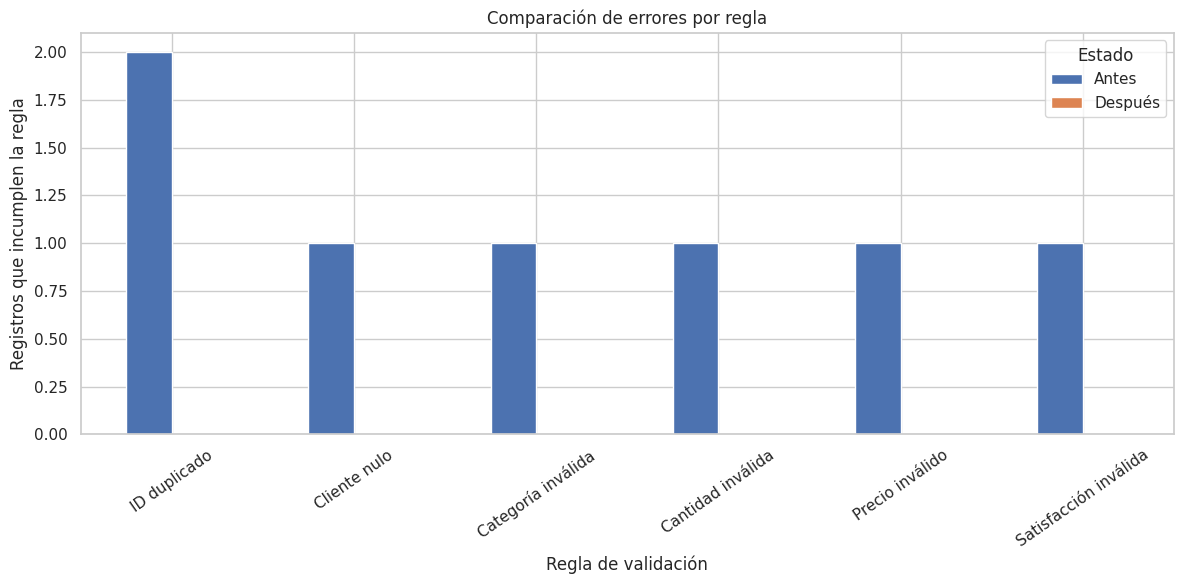

In [ ]:

# ============================================================
# CELDA 8. ERRORES POR TIPO DE REGLA
# ============================================================

def resumen_errores(data):
    return pd.Series({
        "ID duplicado": data["id_venta"].duplicated(
            keep=False
        ).sum(),

        "Cliente nulo": data["cliente"].isna().sum(),

        "Categoría inválida": (
            ~data["categoria"].isin(categorias_validas)
        ).sum(),

        "Cantidad inválida": (data["cantidad"] < 1).sum(),

        "Precio inválido": (
            data["precio_unitario"].isna()
            | (data["precio_unitario"] < 0)
        ).sum(),

        "Satisfacción inválida": (
            ~data["satisfaccion"].isin([1, 2, 3, 4, 5])
        ).sum()
    })


errores_antes = resumen_errores(df)
errores_despues = resumen_errores(df_limpio)

comparacion = pd.DataFrame({
    "Antes": errores_antes,
    "Después": errores_despues
})

display(comparacion)

comparacion.plot(
    kind="bar",
    figsize=(12, 6),
    rot=35
)

plt.title("Comparación de errores por regla")
plt.xlabel("Regla de validación")
plt.ylabel("Registros que incumplen la regla")
plt.legend(title="Estado")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# CELDA 9. EXPORTACIÓN
# ============================================================

# Validación final obligatoria
df_final = esquema_ventas.validate(
    df_limpio,
    lazy=True
)

ruta = "/content/ventas_validadas.csv"

df_final.to_csv(
    ruta,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo generado:", ruta)

from google.colab import files
files.download(ruta)


Archivo generado: /content/ventas_validadas.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>